In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

# If the notebook is inside the notebooks folder, go up one level
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Dataset directory exists:", DATA_DIR.exists())

print("\nFiles and folders in the project:")
for item in sorted(PROJECT_DIR.iterdir()):
    print(item.name)

Project directory: /Users/leeshmaadari/medical-image-classification
Dataset directory: /Users/leeshmaadari/medical-image-classification/data
Dataset directory exists: True

Files and folders in the project:
.ipynb_checkpoints
.venv
data
notebooks


In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_DIR / "data" / "chest_xray"

print("Dataset path:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())

for split in ["train", "test", "val"]:
    split_path = DATA_DIR / split
    print(f"{split}: {split_path.exists()}")

Dataset path: /Users/leeshmaadari/medical-image-classification/data/chest_xray
Dataset exists: True
train: True
test: True
val: True


In [4]:
import pandas as pd

image_extensions = {".jpeg", ".jpg", ".png"}

records = []

for split in ["train", "test", "val"]:
    for label in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / label

        files = [
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        ]

        records.append({
            "Split": split,
            "Class": label,
            "Image Count": len(files)
        })

counts_df = pd.DataFrame(records)
display(counts_df)

,Split,Class,Image Count
0,train,NORMAL,1341
1,train,PNEUMONIA,3875
2,test,NORMAL,234
3,test,PNEUMONIA,390
4,val,NORMAL,8
5,val,PNEUMONIA,8


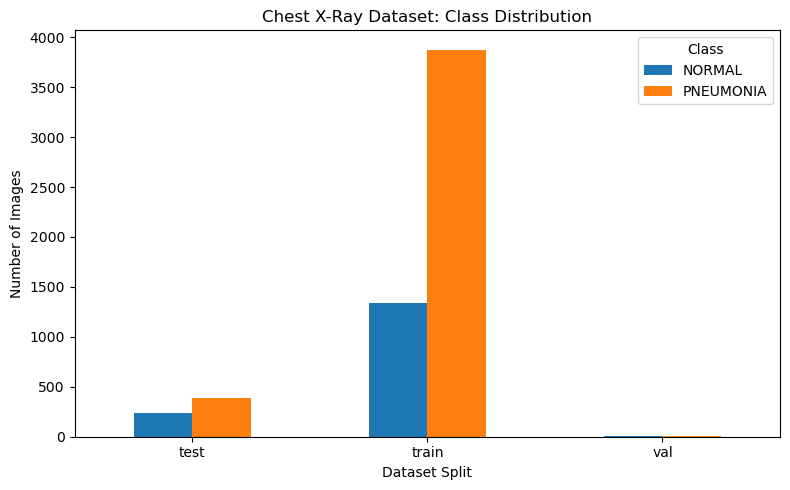

In [5]:
import matplotlib.pyplot as plt

pivot = counts_df.pivot(
    index="Split",
    columns="Class",
    values="Image Count"
)

pivot.plot(kind="bar", figsize=(8, 5))
plt.title("Chest X-Ray Dataset: Class Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

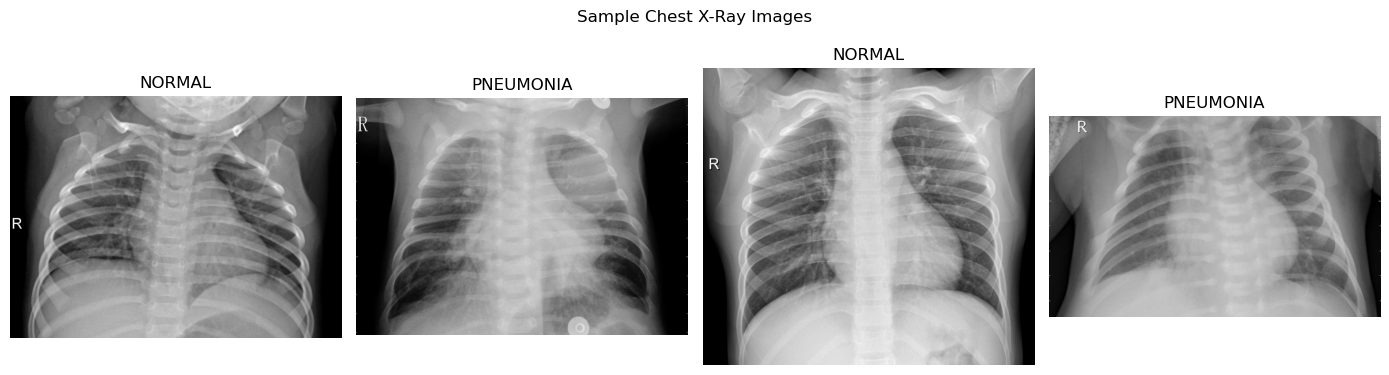

In [6]:
from PIL import Image
import random

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, label in zip(
    axes,
    ["NORMAL", "PNEUMONIA", "NORMAL", "PNEUMONIA"]
):
    folder = DATA_DIR / "train" / label
    images = [
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in image_extensions
    ]

    image_path = random.choice(images)
    image = Image.open(image_path).convert("L")

    ax.imshow(image, cmap="gray")
    ax.set_title(label)
    ax.axis("off")

plt.suptitle("Sample Chest X-Ray Images")
plt.tight_layout()
plt.show()

In [7]:
from PIL import Image
from collections import Counter

image_extensions = {".jpeg", ".jpg", ".png", ".bmp"}

dimension_counts = Counter()
image_modes = Counter()
corrupt_images = []

for label in ["NORMAL", "PNEUMONIA"]:
    folder = DATA_DIR / "train" / label

    for path in folder.iterdir():
        if path.is_file() and path.suffix.lower() in image_extensions:
            try:
                with Image.open(path) as img:
                    dimension_counts[img.size] += 1
                    image_modes[img.mode] += 1
            except Exception:
                corrupt_images.append(str(path))

print("Most common image dimensions:")
for size, count in dimension_counts.most_common(10):
    print(f"{size}: {count} images")

print("\nImage modes:", image_modes)
print("Unreadable images:", len(corrupt_images))

Most common image dimensions:
(1072, 648): 7 images
(1080, 728): 6 images
(976, 672): 5 images
(1008, 704): 5 images
(1064, 760): 5 images
(1216, 872): 5 images
(992, 592): 5 images
(1008, 680): 5 images
(1304, 968): 4 images
(1064, 632): 4 images

Image modes: Counter({'L': 4933, 'RGB': 283})
Unreadable images: 0


In [8]:
counts_df["Percentage within split"] = (
    counts_df["Image Count"]
    / counts_df.groupby("Split")["Image Count"].transform("sum")
    * 100
).round(2)

display(counts_df)

,Split,Class,Image Count,Percentage within split
0,train,NORMAL,1341,25.71
1,train,PNEUMONIA,3875,74.29
2,test,NORMAL,234,37.50
3,test,PNEUMONIA,390,62.50
4,val,NORMAL,8,50.00
5,val,PNEUMONIA,8,50.00


In [9]:
from sklearn.model_selection import train_test_split

IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".png", ".bmp"}

def get_images(split):
    rows = []

    for label, target in [("NORMAL", 0), ("PNEUMONIA", 1)]:
        folder = DATA_DIR / split / label

        for path in folder.iterdir():
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append({
                    "path": str(path),
                    "label": target,
                    "class_name": label,
                    "original_split": split
                })

    return rows

original_train = get_images("train")
original_val = get_images("val")
test_rows = get_images("test")

train_val_df = pd.DataFrame(original_train + original_val)
test_df = pd.DataFrame(test_rows)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.20,
    random_state=42,
    stratify=train_val_df["label"]
)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(df)} images")
    print(df["class_name"].value_counts())


Train: 4185 images
class_name
PNEUMONIA    3106
NORMAL       1079
Name: count, dtype: int64

Validation: 1047 images
class_name
PNEUMONIA    777
NORMAL       270
Name: count, dtype: int64

Test: 624 images
class_name
PNEUMONIA    390
NORMAL       234
Name: count, dtype: int64


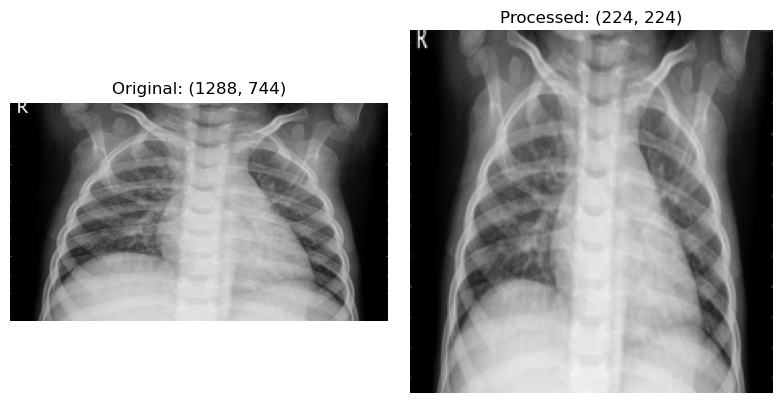

In [10]:
from PIL import Image
import matplotlib.pyplot as plt

sample_path = train_df.iloc[0]["path"]

with Image.open(sample_path) as img:
    original = img.copy()

processed = original.convert("L").resize((224, 224))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original, cmap="gray")
axes[0].set_title(f"Original: {original.size}")
axes[0].axis("off")

axes[1].imshow(processed, cmap="gray")
axes[1].set_title(f"Processed: {processed.size}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path

PROCESSED_DIR = PROJECT_DIR / "data" / "processed_224_gray"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Processed dataset will be saved to:")
print(PROCESSED_DIR)


Processed dataset will be saved to:
/Users/leeshmaadari/medical-image-classification/data/processed_224_gray


In [12]:
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

IMAGE_SIZE = (224, 224)

def preprocess_split(df, split_name):
    images = np.empty(
        (len(df), 224, 224),
        dtype=np.uint8
    )
    labels = df["label"].to_numpy(dtype=np.int64)

    for i, path in enumerate(tqdm(
        df["path"],
        desc=f"Processing {split_name}"
    )):
        with Image.open(path) as img:
            img = img.convert("L").resize(
                IMAGE_SIZE,
                Image.Resampling.LANCZOS
            )
            images[i] = np.asarray(img, dtype=np.uint8)

    output_path = PROCESSED_DIR / f"{split_name}.npz"

    np.savez_compressed(
        output_path,
        images=images,
        labels=labels
    )

    print(f"Saved: {output_path}")
    print(f"Images shape: {images.shape}")
    print(f"Labels shape: {labels.shape}")
    print(f"File size: {output_path.stat().st_size / (1024**2):.2f} MB")

    return images, labels

X_train, y_train = preprocess_split(train_df, "train")
X_val, y_val = preprocess_split(val_df, "validation")
X_test, y_test = preprocess_split(test_df, "test")

Processing train:   0%|          | 0/4185 [00:00<?, ?it/s]

Saved: /Users/leeshmaadari/medical-image-classification/data/processed_224_gray/train.npz
Images shape: (4185, 224, 224)
Labels shape: (4185,)
File size: 157.80 MB


Processing validation:   0%|          | 0/1047 [00:00<?, ?it/s]

Saved: /Users/leeshmaadari/medical-image-classification/data/processed_224_gray/validation.npz
Images shape: (1047, 224, 224)
Labels shape: (1047,)
File size: 39.53 MB


Processing test:   0%|          | 0/624 [00:00<?, ?it/s]

Saved: /Users/leeshmaadari/medical-image-classification/data/processed_224_gray/test.npz
Images shape: (624, 224, 224)
Labels shape: (624,)
File size: 23.64 MB


In [13]:
for file in sorted(PROCESSED_DIR.glob("*.npz")):
    with np.load(file) as data:
        print(
            file.name,
            "| images:", data["images"].shape,
            "| labels:", data["labels"].shape,
            "| dtype:", data["images"].dtype
        )

test.npz | images: (624, 224, 224) | labels: (624,) | dtype: uint8
train.npz | images: (4185, 224, 224) | labels: (4185,) | dtype: uint8
validation.npz | images: (1047, 224, 224) | labels: (1047,) | dtype: uint8
